# Álgebra lineal: SVD y PCA
## Ejercicio 7: Descomposición en valores singulares (SVD)
Descompongo una matriz con `np.linalg.svd`, la reconstruyo y estudio la aproximación de rango bajo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
A = np.array([[3,1],[1,3],[0,2]])
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print(np.shape(U),np.shape(s),np.shape(Vt))
print(np.diag(s))

(3, 2) (2,) (2, 2)
[[4.28071902 0.        ]
 [0.         2.38231918]]


In [3]:
A_rec = U @ np.diag(s) @ Vt
print(f"A es igual a U @ np.diag(s) @ Vt -> {np.allclose(A, A_rec)}")

A es igual a U @ np.diag(s) @ Vt -> True


In [4]:
#Aproximación con rango = 1
A1 = s[0] * np.outer(U[:,0], Vt[0,:])
print(A1)
print(np.linalg.norm(A - A1)) #Error de A1 respecto a A: coincide con el segundo valor singular.

[[1.5        2.08113883]
 [1.76491106 2.4486833 ]
 [0.9486833  1.31622777]]
2.3823191808956334


In [5]:
#Cuanto es lo que realmente captura el rango 1:
energia = s**2 / np.sum(s**2)
for i in range(len(energia)):
    print(f"El componente {i+1}, guarda el {energia[i]:1%} % de la información")

El componente 1, guarda el 76.352314% % de la información
El componente 2, guarda el 23.647686% % de la información


In [6]:
#Caso de control
A2 = s[0]*np.outer(U[:,0], Vt[0,:]) + s[1]*np.outer(U[:,1], Vt[1,:])
print(np.linalg.norm(A - A2))

3.0201331455116262e-15


In [7]:
#Orthonormalidad
# Ut@U = I (matriz identidad)
print(np.round(U.T@U,6))

[[1. 0.]
 [0. 1.]]


**Conclusión:** Descompuse A (3×2) con `np.linalg.svd` y verifiqué que U @ diag(s) @ Vᵀ reconstruye A. Los valores singulares (4.28 y 2.38) están ordenados de mayor a menor. Con solo el primero, la aproximación de rango 1 captura cerca del 76% de la información, y el error de reconstrucción (2.38) es justo el valor singular descartado. Al usar los dos componentes el error es casi 0. Esto muestra que los valores singulares miden la importancia de cada componente y que se pueden omitir los pequeños para comprimir una matriz.

## Ejercicio 8: Mínimos Cuadrados

In [8]:
rng = np.random.default_rng(0)
x = np.linspace(0,10,30)
y = 2*x + 1 + rng.normal(0,1,30)
#Matriz de diseño
X = np.column_stack([x, np.ones_like(x)])
coef, residuos, rango, sv = np.linalg.lstsq(X,y,rcond=None)
print(f"Pendiente: {coef[0]} \nIntercepto: {coef[1]}")

Pendiente: 1.990391460416812 
Intercepto: 0.926556198157298


In [9]:
#Comparación
print(f"Valores de linalg.lstsq son iguales a los de polyfit -> {np.allclose(coef, np.polyfit(x, y, 1))}")

Valores de linalg.lstsq son iguales a los de polyfit -> True


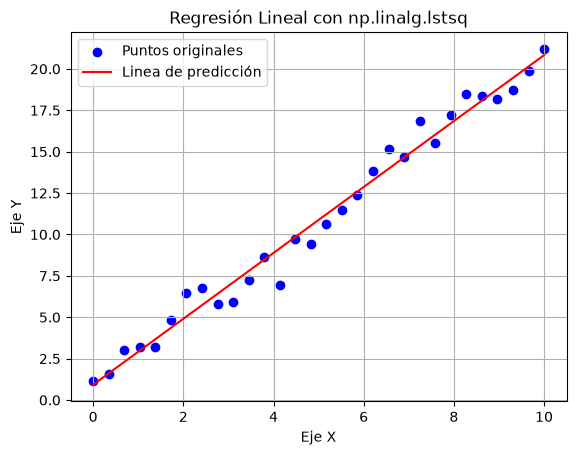

In [10]:
#Grafica
m, b = coef
y_pred = m * x + b

plt.figure()
plt.scatter(x,y,label="Puntos originales", color="b")
plt.plot(x,y_pred,label="Linea de predicción", color="r")
plt.xlabel('Eje X')
plt.ylabel('Eje Y')
plt.title('Regresión Lineal con np.linalg.lstsq')
plt.legend()
plt.grid()
plt.show()

In [11]:
#Acercamiento
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - (residuos[0] / ss_tot)
print(f"R² (Calidad del ajuste): {r2:.4f}")

R² (Calidad del ajuste): 0.9818


In [12]:
#Conexión con proyección: Mínimos cuadrados proyecta y sobre el espacio generado por columnas de X.
residuo = y - X @ coef
print(X.T @ residuo) #Debe de ser cercano a [0,0]

[-3.02424752e-13 -5.28466160e-14]


**Conclusión:** Generé 30 puntos ruidosos de la recta y = 2x + 1 y construí la matriz de diseño X = [x, 1]. Con `np.linalg.lstsq` obtuve una pendiente de 1.99 y un intercepto de 0.93, muy cercanos a los valores reales (2 y 1), y coincidieron con `np.polyfit`. El ajuste tiene R² = 0.98. No salen exactos por el ruido y el número limitado de puntos. Mínimos cuadrados equivale a proyectar y sobre el espacio generado por las columnas de X, por eso el residuo queda perpendicular a ese espacio.